# Predicción de abandono de clientes (churn) en telecomunicaciones
**Grupo 4 – 1INF24 – Tarea Académica de Inteligencia Artificial**

Castillo Causillas, Helen Jannet · Mamani Mamani, Enzo Fabio · Alvarez Rosas, Belén Lucía · Suppe Tejada, Nicole Andrea

Notebook con el preprocesamiento, el análisis exploratorio, los experimentos y los resultados del informe final
(entregado como `H0781_Grupo4_Articulo.pdf`). Las letras (A)–(E) coinciden con los apartados de la Metodología del informe.

**Contenido:**
1. Configuración inicial
2. Carga del conjunto de datos
3. Análisis exploratorio de datos (EDA)
4. (A) Limpieza inicial e ingeniería de atributos
5. (B) Partición estratificada y pliegues de validación cruzada
6. (C) Codificación, escalamiento y tratamiento del desbalance (S0, S1, S2 = SMOTE-NC)
7. (D) Modelos de clasificación: M1 regresión logística, M2 árbol CART y M3 híbrido árbol + RL
8. (E) Ajuste del umbral de decisión
9. Experimentos: 3 modelos × 3 estrategias de balanceo
10. Resultados: Tabla 3, modelo seleccionado e hipótesis H1
11. Efecto del umbral y del balanceo (Fig. 2, Tabla 4, hipótesis H2)
12. Influencia de los hiperparámetros
13. Curvas ROC (Fig. 3)
14. Interpretabilidad (hipótesis H3)
15. Implicancias éticas: auditoría de sesgos
16. Guardado de resultados

La semilla aleatoria es fija (42), por lo que el notebook produce siempre los mismos resultados.
La ejecución completa tarda entre 5 y 10 minutos; la mayor parte del tiempo corresponde a SMOTE-NC.

## 1. Configuración inicial

In [1]:
# Cargamos las librerías necesarias para el preprocesamiento, el análisis exploratorio,
# el entrenamiento de los modelos y su evaluación.
import json
import os
import time
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Preprocesamiento y partición de los datos
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split

# Modelos de clasificación
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text

# Métricas de evaluación de clasificadores
from sklearn.metrics import (confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)

# Ocultamos avisos que no afectan los resultados (convergencia y cambios futuros de la API
# de scikit-learn) para que las salidas del notebook se lean con claridad.
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*penalty.*")

SEED = 42  # semilla fija: todos los resultados son reproducibles
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Carga del conjunto de datos

In [2]:
# Usamos el conjunto público Telco Customer Churn de IBM [8]
# (https://www.kaggle.com/datasets/blastchar/telco-customer-churn).
# El CSV está en la carpeta data/ del repositorio. Si el notebook se ejecuta en Google Colab
# sin clonar el repositorio, se descarga desde GitHub.
RUTA_LOCAL = "data/telco.csv"
URL_GITHUB = "https://raw.githubusercontent.com/LoXxO-Dev/Tarea_Academica_IA/main/data/telco.csv"

raw = pd.read_csv(RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else URL_GITHUB)
print(f"Dimensiones del conjunto de datos: {raw.shape}")
raw.head()

Dimensiones del conjunto de datos: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Revisamos los tipos de dato. TotalCharges aparece como texto (str) aunque es numérica:
# se corrige en la limpieza (A).
raw.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

## 3. Análisis exploratorio de datos (EDA)

In [4]:
# Verificamos que no existan registros duplicados ni valores nulos explícitos.
print("Clientes duplicados (customerID):", raw["customerID"].duplicated().sum())
print("Valores nulos por columna:", int(raw.isnull().sum().sum()))

# Los valores vacíos de TotalCharges vienen como texto en blanco (" "), no como NaN.
blancos = raw["TotalCharges"].astype(str).str.strip() == ""
print("TotalCharges vacíos:", int(blancos.sum()))
print("tenure de esos clientes:", raw.loc[blancos, "tenure"].unique())
# Los 11 vacíos corresponden a clientes con tenure = 0 (recién afiliados que aún no han sido facturados).

Clientes duplicados (customerID): 0
Valores nulos por columna: 0
TotalCharges vacíos: 11
tenure de esos clientes: [0]


       clientes  porcentaje
Churn                      
No         5174        73.5
Yes        1869        26.5


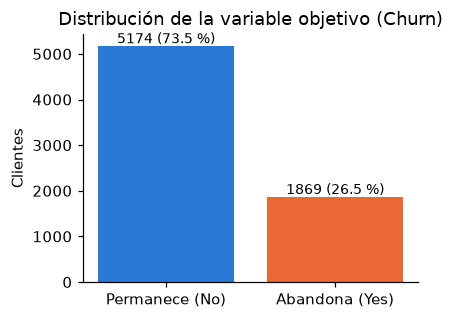

In [5]:
# Distribución de la variable objetivo: el problema es desbalanceado.
conteo = raw["Churn"].value_counts()
print(pd.DataFrame({"clientes": conteo, "porcentaje": (100 * conteo / len(raw)).round(1)}))

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(["Permanece (No)", "Abandona (Yes)"], conteo.values, color=["#2a78d6", "#eb6834"])
for i, v in enumerate(conteo.values):
    ax.text(i, v + 60, f"{v} ({100 * v / len(raw):.1f} %)", ha="center", fontsize=9)
ax.set_ylabel("Clientes")
ax.set_title("Distribución de la variable objetivo (Churn)")
plt.tight_layout()
plt.show()
# Solo el 26,5 % de los clientes abandona: la exactitud (accuracy) sería engañosa como métrica.

In [6]:
# Tasa de abandono según las variables categóricas de contrato y servicio, para identificar
# los factores asociados al abandono antes de modelar.
for col in ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling", "SeniorCitizen"]:
    t = raw.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()).mul(100).round(1)
    print(f"\nTasa de abandono (%) por {col}:")
    print(t.to_string())
# Los contratos mes a mes, la fibra óptica y el pago con cheque electrónico concentran el abandono.


Tasa de abandono (%) por Contract:
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8

Tasa de abandono (%) por InternetService:
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4

Tasa de abandono (%) por PaymentMethod:
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1

Tasa de abandono (%) por PaperlessBilling:
PaperlessBilling
No     16.3
Yes    33.6

Tasa de abandono (%) por SeniorCitizen:
SeniorCitizen
0    23.6
1    41.7


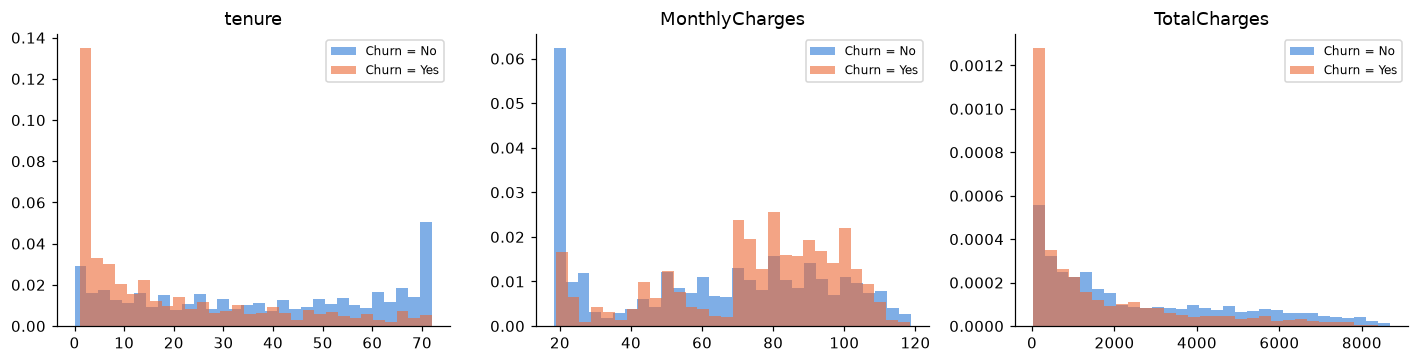

In [7]:
# Distribución de las variables numéricas según la clase.
num = raw.assign(TotalCharges=pd.to_numeric(raw["TotalCharges"], errors="coerce"))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    for lab, color in [("No", "#2a78d6"), ("Yes", "#eb6834")]:
        ax.hist(num.loc[num["Churn"] == lab, col].dropna(), bins=30, alpha=0.6, color=color,
                label=f"Churn = {lab}", density=True)
    ax.set_title(col)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
# Los clientes que abandonan tienen menor antigüedad (tenure) y cargos mensuales más altos.

In [8]:
# Correlación de Pearson entre las variables numéricas originales.
num[["tenure", "MonthlyCharges", "TotalCharges"]].corr().round(2)
# TotalCharges está muy correlacionada con tenure (es aproximadamente tenure × cargo mensual).

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


## 4. (A) Limpieza inicial e ingeniería de atributos
Solo se aplican reglas fijas fila por fila. No se calcula ninguna estadística del conjunto,
por lo que esta etapa puede hacerse antes de la partición sin fuga de información.

In [9]:
# Grupos de variables. Los seis servicios adicionales se usan también para contar n_services.
SERVICES = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies"]
BINARY = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
          "MultipleLines", "PaperlessBilling"] + SERVICES
NOMINAL = ["InternetService", "Contract", "PaymentMethod"]
NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges", "n_services",
           "avg_charge", "charge_diff"]
FEATURES = BINARY + NOMINAL + NUMERIC


def clean_and_engineer(raw):
    df = raw.copy()
    # Limpieza: TotalCharges a numérico; los 11 vacíos (tenure = 0) reciben 0, su valor real.
    total = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")
    n_blank = int(total.isna().sum())
    assert (df.loc[total.isna(), "tenure"] == 0).all(), "vacíos con tenure != 0"
    df["TotalCharges"] = total.fillna(0.0)
    # Reducción de redundancia: «No internet service» y «No phone service» se recodifican como «No».
    df = df.replace({"No internet service": "No", "No phone service": "No"})
    # Ingeniería de atributos (inspirada en [3]).
    df["n_services"] = (df[SERVICES] == "Yes").sum(axis=1).astype(float)    # servicios adicionales
    df["avg_charge"] = df["TotalCharges"] / df["tenure"].clip(lower=1)       # cargo promedio histórico
    df["charge_diff"] = df["MonthlyCharges"] - df["avg_charge"]              # incremento reciente de precio
    # Variables binarias a {0, 1}.
    for c in BINARY:
        if c == "gender":
            df[c] = (df[c] == "Male").astype(int)
        elif c != "SeniorCitizen":
            df[c] = (df[c] == "Yes").astype(int)
    df["tenure"] = df["tenure"].astype(float)
    y = (df["Churn"] == "Yes").astype(int).to_numpy()
    # customerID se excluye (no aporta información) y Churn es la etiqueta.
    return df[FEATURES].reset_index(drop=True), y, n_blank


X, y, n_blank = clean_and_engineer(raw)
info = dict(n=len(y), churners=int(y.sum()), pi=float(y.mean()), blank_total=n_blank)
print(f"Clientes: {info['n']} | abandonos: {info['churners']} ({100 * info['pi']:.1f} %) | "
      f"TotalCharges vacíos imputados con 0: {n_blank}")
print(f"Atributos tras la limpieza: {X.shape[1]} (19 originales + 3 nuevos)")
X.head()

Clientes: 7043 | abandonos: 1869 (26.5 %) | TotalCharges vacíos imputados con 0: 11
Atributos tras la limpieza: 22 (19 originales + 3 nuevos)


,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,PaperlessBilling,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetService,Contract,PaymentMethod,tenure,MonthlyCharges,TotalCharges,n_services,avg_charge,charge_diff
0,0,0,1,0,0,0,1,0,1,0,0,0,0,DSL,Month-to-month,Electronic check,1.0,29.85,29.85,1.0,29.850000,0.000000
1,1,0,0,0,1,0,0,1,0,1,0,0,0,DSL,One year,Mailed check,34.0,56.95,1889.50,2.0,55.573529,1.376471
2,1,0,0,0,1,0,1,1,1,0,0,0,0,DSL,Month-to-month,Mailed check,2.0,53.85,108.15,2.0,54.075000,-0.225000
3,1,0,0,0,0,0,0,1,0,1,1,0,0,DSL,One year,Bank transfer (automatic),45.0,42.30,1840.75,3.0,40.905556,1.394444
4,0,0,0,0,1,0,1,0,0,0,0,0,0,Fiber optic,Month-to-month,Electronic check,2.0,70.70,151.65,0.0,75.825000,-5.125000


## 5. (B) Partición estratificada y pliegues de validación cruzada

In [10]:
# Partición estratificada 80/20: el conjunto de prueba se aparta y solo se usa en la evaluación final.
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
Xtr, Xte = Xtr.reset_index(drop=True), Xte.reset_index(drop=True)

# Validación cruzada estratificada de 5 pliegues sobre el entrenamiento, para elegir hiperparámetros.
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xtr, ytr))
info.update(n_train=len(ytr), n_test=len(yte), churn_train=int(ytr.sum()), churn_test=int(yte.sum()))

print(f"Entrenamiento: {len(ytr)} clientes ({ytr.sum()} abandonos, {100 * ytr.mean():.1f} %)")
print(f"Prueba:        {len(yte)} clientes ({yte.sum()} abandonos, {100 * yte.mean():.1f} %)")
for f, (itr, iva) in enumerate(folds):
    print(f"  Pliegue {f + 1}: {len(itr)} para ajustar, {len(iva)} para validar "
          f"({100 * ytr[iva].mean():.1f} % abandonos)")

Entrenamiento: 5634 clientes (1495 abandonos, 26.5 %)
Prueba:        1409 clientes (374 abandonos, 26.5 %)
  Pliegue 1: 4507 para ajustar, 1127 para validar (26.5 % abandonos)
  Pliegue 2: 4507 para ajustar, 1127 para validar (26.5 % abandonos)
  Pliegue 3: 4507 para ajustar, 1127 para validar (26.5 % abandonos)
  Pliegue 4: 4507 para ajustar, 1127 para validar (26.5 % abandonos)
  Pliegue 5: 4508 para ajustar, 1126 para validar (26.6 % abandonos)


## 6. (C) Codificación, escalamiento y tratamiento del desbalance
Todo lo que aprende parámetros de los datos (codificador, escalador, SMOTE-NC) se ajusta solo con los
datos de entrenamiento de cada pliegue, dentro de la función `prepare`.

In [11]:
# Codificación y escalamiento:
#  - numéricas: estandarización z = (x - media) / desviación estándar (solo con entrenamiento);
#  - nominales: One-Hot Encoding; en M1 y M3 se elimina una categoría de referencia (drop="first");
#  - binarias: ya están en {0, 1} y pasan sin cambios.
def make_preprocessor(drop_first):
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("nom", OneHotEncoder(drop="first" if drop_first else None,
                              handle_unknown="ignore", sparse_output=False), NOMINAL),
        ("bin", "passthrough", BINARY),
    ], verbose_feature_names_out=False)


n_feat_drop = len(make_preprocessor(True).fit(Xtr).get_feature_names_out())
n_feat_full = len(make_preprocessor(False).fit(Xtr).get_feature_names_out())
print(f"Atributos tras la codificación: M1 y M3 = {n_feat_drop}; M2 (árbol, sin categoría de referencia) = {n_feat_full}")

Atributos tras la codificación: M1 y M3 = 26; M2 (árbol, sin categoría de referencia) = 29


In [12]:
# S1 – Pesos por clase: w_c = N / (2 N_c), calculados con el entrenamiento.
w_s1 = {c: len(ytr) / (2 * (ytr == c).sum()) for c in (0, 1)}
print(f"Peso de un no churner: {w_s1[0]:.2f} | peso de un churner: {w_s1[1]:.2f} | "
      f"razón: {w_s1[1] / w_s1[0]:.1f}")

Peso de un no churner: 0.68 | peso de un churner: 1.88 | razón: 2.8


In [13]:
# S2 – SMOTE-NC (Chawla et al., 2002 [7]), programado sobre numpy/scikit-learn.
#  - Distancia: euclidiana sobre las numéricas estandarizadas + med^2 por cada categórica distinta,
#    donde med es la mediana de las desviaciones estándar de las numéricas en la clase minoritaria.
#  - Numéricas: interpolación entre el cliente base y un vecino; categóricas: moda de los k vecinos.
#  - n_services se recalcula a partir de los servicios sintéticos.

def vecinos_mas_cercanos(M, k):
    # Los k vecinos más cercanos de cada fila, excluyendo a la propia fila.
    # Como la mayoría de atributos son categóricos, hay muchas distancias empatadas. Las distancias
    # se redondean y los empates se resuelven por el índice del cliente (orden estable), de modo que
    # el resultado sea idéntico en cualquier computadora, sin depender de la librería numérica.
    sq = (M ** 2).sum(axis=1)
    D = np.round(np.maximum(sq[:, None] + sq[None, :] - 2 * M @ M.T, 0), 8)
    np.fill_diagonal(D, np.inf)
    return np.argsort(D, axis=1, kind="stable")[:, :k]


def smote_nc(X, y, k=5, seed=SEED):
    rng = np.random.default_rng(seed)
    cat_cols = BINARY + NOMINAL
    num_cols = [c for c in NUMERIC if c != "n_services"]
    Xmin = X[y == 1].reset_index(drop=True)
    n_new = int((y == 0).sum() - (y == 1).sum())   # se generan sintéticos hasta igualar las clases
    if n_new <= 0:
        return X, y
    mu, sd = X[num_cols].mean(), X[num_cols].std(ddof=0).replace(0, 1.0)
    Z = ((Xmin[num_cols] - mu) / sd).to_numpy()
    med = float(np.median(Z.std(axis=0)))
    C = pd.get_dummies(Xmin[cat_cols].astype(str)).to_numpy(dtype=float) * med / np.sqrt(2)
    neigh = vecinos_mas_cercanos(np.hstack([Z, C]), k)
    base = rng.integers(0, len(Xmin), n_new)                  # cliente base de cada sintético
    pick = neigh[base, rng.integers(0, k, n_new)]             # vecino elegido al azar
    gap = rng.random(n_new)[:, None]
    num_base = Xmin[num_cols].to_numpy()
    syn = pd.DataFrame(num_base[base] + gap * (num_base[pick] - num_base[base]), columns=num_cols)
    for c in cat_cols:
        vals = Xmin[c].to_numpy()[neigh[base]]                # (n_new, k)
        syn[c] = pd.DataFrame(vals).mode(axis=1)[0].to_numpy()
        syn[c] = syn[c].astype(Xmin[c].dtype)
    syn["n_services"] = syn[SERVICES].sum(axis=1).astype(float)
    Xr = pd.concat([X, syn[X.columns]], ignore_index=True)
    yr = np.concatenate([y, np.ones(n_new, dtype=int)])
    return Xr, yr


# Ejemplo sobre todo el entrenamiento: SMOTE-NC iguala ambas clases.
Xs, ys = smote_nc(Xtr, ytr)
print(f"Antes:   {len(ytr)} clientes, {ytr.sum()} abandonos ({100 * ytr.mean():.1f} %)")
print(f"Después: {len(ys)} clientes, {ys.sum()} abandonos ({100 * ys.mean():.1f} %)")
Xs.tail(3)

Antes:   5634 clientes, 1495 abandonos (26.5 %)
Después: 8278 clientes, 4139 abandonos (50.0 %)


,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,PaperlessBilling,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetService,Contract,PaymentMethod,tenure,MonthlyCharges,TotalCharges,n_services,avg_charge,charge_diff
8275,1,0,0,0,1,0,1,0,0,0,0,0,1,Fiber optic,Month-to-month,Electronic check,1.00000,80.833686,80.833686,1.0,80.833686,0.000000
8276,0,0,1,0,1,0,1,0,0,1,0,0,0,Fiber optic,Month-to-month,Bank transfer (automatic),5.07519,71.942935,355.338083,1.0,69.245148,2.697786
8277,1,0,0,0,1,0,1,0,0,0,0,0,0,DSL,Month-to-month,Mailed check,1.00000,45.406140,45.406140,0.0,45.406140,0.000000


In [14]:
# prepare(): aplica S2 (si corresponde) y ajusta el preprocesador SOLO con los datos de entrenamiento
# recibidos; así se evita la fuga de información durante la validación cruzada.
def prepare(Xtr, ytr, strategy, drop_first, seed):
    if strategy == "S2":
        Xtr, ytr = smote_nc(Xtr, ytr, seed=seed)
    pre = make_preprocessor(drop_first).fit(Xtr)
    return pre, pre.transform(Xtr), ytr

## 7. (D) Modelos de clasificación
- **M1 – Regresión logística regularizada** (L1 o L2), con los coeficientes interpretados como razones de momios.
- **M2 – Árbol de decisión CART** (Gini), con profundidad máxima, tamaño mínimo de hoja y poda por complejidad α.
- **M3 – Modelo híbrido árbol + RL** (Logit Leaf Model [4]): un árbol poco profundo segmenta a los clientes
  y en cada hoja se ajusta una regresión logística propia.

In [15]:
class LogitLeaf:
    # M3: árbol poco profundo (mínimo 10 % de los clientes por hoja) + regresión logística por hoja.

    def __init__(self, depth, C, class_weight):
        self.depth, self.C, self.class_weight = depth, C, class_weight

    def fit(self, X, y):
        self.tree = DecisionTreeClassifier(max_depth=self.depth, min_samples_leaf=0.10,
                                           class_weight=self.class_weight,
                                           random_state=SEED).fit(X, y)
        leaves = self.tree.apply(X)
        self.models = {}
        for leaf in np.unique(leaves):
            m = leaves == leaf
            if len(np.unique(y[m])) < 2:          # hoja pura: probabilidad constante
                self.models[leaf] = float(y[m].mean())
            else:
                self.models[leaf] = LogisticRegression(
                    C=self.C, penalty="l2", class_weight=self.class_weight,
                    max_iter=2000).fit(X[m], y[m])
        return self

    def predict_proba(self, X):
        # Cada cliente se enruta a su segmento y recibe la probabilidad de la RL de esa hoja.
        leaves = self.tree.apply(X)
        p = np.zeros(len(X))
        for leaf, mdl in self.models.items():
            m = leaves == leaf
            if m.any():
                p[m] = mdl if isinstance(mdl, float) else mdl.predict_proba(X[m])[:, 1]
        return np.column_stack([1 - p, p])


# Espacio de búsqueda de hiperparámetros (Tabla 2 del informe).
GRIDS = {
    "M1": [dict(C=C, penalty=p) for C, p in product([0.01, 0.1, 1, 10], ["l1", "l2"])],
    "M2": [dict(max_depth=d, min_samples_leaf=m, ccp_alpha=a)
           for d, m, a in product([3, 4, 5, 6, 8, 10], [5, 10, 20, 50], [0, 0.001, 0.005, 0.01])],
    "M3": [dict(depth=d, C=C) for d, C in product([2, 3], [0.1, 1, 10])],
}
print({m: len(g) for m, g in GRIDS.items()}, "combinaciones por estrategia de balanceo")


def build(model, params, class_weight):
    if model == "M1":
        return LogisticRegression(C=params["C"], penalty=params["penalty"], solver="liblinear",
                                  class_weight=class_weight, max_iter=2000, random_state=SEED)
    if model == "M2":
        return DecisionTreeClassifier(**params, class_weight=class_weight, random_state=SEED)
    return LogitLeaf(params["depth"], params["C"], class_weight)

{'M1': 8, 'M2': 96, 'M3': 6} combinaciones por estrategia de balanceo


## 8. (E) Ajuste del umbral de decisión
Con las predicciones fuera de pliegue (out-of-fold) se recorren los umbrales τ entre 0,05 y 0,95 con paso 0,01
y se elige, según la Ec. (3), el de mayor precisión entre los que garantizan Recall ≥ 0,80. Si ninguno lo
alcanza, se usa el que maximiza el F1-Score.

In [16]:
def choose_threshold(y, p, target=0.80):
    rule = "recall>=0.80"
    grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
    rows = []
    for t in grid:
        pred = (p >= t).astype(int)
        rows.append((t, recall_score(y, pred), precision_score(y, pred, zero_division=0),
                     f1_score(y, pred, zero_division=0)))
    ok = [r for r in rows if r[1] >= target]
    if ok:
        best = max(ok, key=lambda r: (r[2], r[0]))
    else:
        best, rule = max(rows, key=lambda r: r[3]), "max F1"
    return float(best[0]), rule, rows


def metrics(y, p, t):
    # Recall, Precision, F1 y ROC-AUC, más la matriz de confusión, para un umbral t.
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(recall=recall_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0), auc=roc_auc_score(y, p),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

## 9. Experimentos: 3 modelos × 3 estrategias de balanceo
Para cada una de las nueve configuraciones:
1. se recorre la rejilla con validación cruzada de 5 pliegues y se elige la combinación de mayor ROC-AUC promedio;
2. con las predicciones fuera de pliegue de esa combinación se fija τ*;
3. el modelo se reentrena con todo el entrenamiento y se evalúa **una sola vez** en prueba (con τ* y con τ = 0,5).

Esta celda tarda varios minutos (S2 concentra la mayor parte del tiempo por la búsqueda de vecinos).

In [17]:
t_start = time.time()
cv_rows, final, modelos = [], {}, {}
for model, strategy in product(["M1", "M2", "M3"], ["S0", "S1", "S2"]):
    t0 = time.time()
    drop_first = model != "M2"
    cw = w_s1 if strategy == "S1" else None
    grid = GRIDS[model]
    aucs = np.zeros((len(grid), 5))
    preds = np.zeros((len(grid), len(ytr)))
    # Búsqueda en rejilla con validación cruzada (todo se ajusta solo con el pliegue de entrenamiento).
    for f, (itr, iva) in enumerate(folds):
        pre, A, b = prepare(Xtr.iloc[itr].reset_index(drop=True), ytr[itr], strategy, drop_first, SEED + f)
        V = pre.transform(Xtr.iloc[iva])
        for g, params in enumerate(grid):
            p = build(model, params, cw).fit(A, b).predict_proba(V)[:, 1]
            preds[g, iva] = p
            aucs[g, f] = roc_auc_score(ytr[iva], p)
    for g, params in enumerate(grid):
        cv_rows.append(dict(model=model, strategy=strategy, **params,
                            auc_mean=aucs[g].mean(), auc_std=aucs[g].std()))
    g_best = int(np.argmax(aucs.mean(axis=1)))
    params = grid[g_best]
    p_oof = preds[g_best]
    # Umbral τ* con las predicciones fuera de pliegue.
    tau, rule, curve = choose_threshold(ytr, p_oof)
    fold_metric = lambda fn, t: [float(fn(ytr[iva], (p_oof[iva] >= t).astype(int), zero_division=0))
                                 for _, iva in folds]
    # Modelo final: reentrenamiento con el 80 % y evaluación única en prueba.
    pre, A, b = prepare(Xtr, ytr, strategy, drop_first, SEED)
    clf = build(model, params, cw).fit(A, b)
    p_te = clf.predict_proba(pre.transform(Xte))[:, 1]
    key = f"{model}-{strategy}"
    modelos[key] = (pre, clf)
    final[key] = dict(
        model=model, strategy=strategy, params=params,
        cv_auc_mean=float(aucs[g_best].mean()), cv_auc_std=float(aucs[g_best].std()),
        cv_auc_folds=[float(a) for a in aucs[g_best]], tau=tau, tau_rule=rule,
        oof_at_tau=metrics(ytr, p_oof, tau), oof_at_05=metrics(ytr, p_oof, 0.5),
        fold_recall_tau=fold_metric(recall_score, tau), fold_recall_05=fold_metric(recall_score, 0.5),
        fold_prec_tau=fold_metric(precision_score, tau), fold_prec_05=fold_metric(precision_score, 0.5),
        test_at_tau=metrics(yte, p_te, tau), test_at_05=metrics(yte, p_te, 0.5),
        seconds=round(time.time() - t0, 1),
        threshold_curve=[[float(v) for v in r] for r in curve],
        roc_test=[a.tolist() for a in roc_curve(yte, p_te)[:2]],
        p_test=p_te.tolist(),
    )
    t = final[key]["test_at_tau"]
    print(f"{key}: {params} | AUC VC {aucs[g_best].mean():.4f} | τ* {tau:.2f} | prueba: "
          f"Rec {t['recall']:.3f} Prec {t['precision']:.3f} AUC {t['auc']:.4f} | {final[key]['seconds']} s",
          flush=True)

info["total_seconds"] = round(time.time() - t_start, 1)
cv_grid = pd.DataFrame(cv_rows)
print(f"\nAjustes realizados: {len(cv_grid) * 5} | tiempo total: {info['total_seconds']} s")

M1-S0: {'C': 10, 'penalty': 'l2'} | AUC VC 0.8458 | τ* 0.26 | prueba: Rec 0.791 Prec 0.503 AUC 0.8415 | 10.6 s


M1-S1: {'C': 10, 'penalty': 'l2'} | AUC VC 0.8457 | τ* 0.50 | prueba: Rec 0.786 Prec 0.505 AUC 0.8409 | 18.7 s


M1-S2: {'C': 0.01, 'penalty': 'l2'} | AUC VC 0.8401 | τ* 0.44 | prueba: Rec 0.802 Prec 0.498 AUC 0.8318 | 86.5 s


M2-S0: {'max_depth': 5, 'min_samples_leaf': 50, 'ccp_alpha': 0} | AUC VC 0.8290 | τ* 0.22 | prueba: Rec 0.818 Prec 0.483 AUC 0.8329 | 19.5 s


M2-S1: {'max_depth': 5, 'min_samples_leaf': 10, 'ccp_alpha': 0} | AUC VC 0.8278 | τ* 0.46 | prueba: Rec 0.826 Prec 0.504 AUC 0.8342 | 19.6 s


M2-S2: {'max_depth': 8, 'min_samples_leaf': 10, 'ccp_alpha': 0.001} | AUC VC 0.8209 | τ* 0.34 | prueba: Rec 0.810 Prec 0.460 AUC 0.8174 | 105.6 s


M3-S0: {'depth': 2, 'C': 1} | AUC VC 0.8447 | τ* 0.24 | prueba: Rec 0.816 Prec 0.501 AUC 0.8439 | 7.9 s


M3-S1: {'depth': 2, 'C': 0.1} | AUC VC 0.8448 | τ* 0.48 | prueba: Rec 0.813 Prec 0.512 AUC 0.8438 | 7.5 s


M3-S2: {'depth': 3, 'C': 0.1} | AUC VC 0.8351 | τ* 0.42 | prueba: Rec 0.813 Prec 0.481 AUC 0.8327 | 86.3 s



Ajustes realizados: 1650 | tiempo total: 362.2 s


## 10. Resultados: Tabla 3, modelo seleccionado e hipótesis H1

In [18]:
# Referencia trivial: predecir siempre la clase mayoritaria («permanece»).
info["trivial"] = dict(accuracy=float((yte == 0).mean()), recall=0.0, precision=0.0, f1=0.0, auc=0.5)
print(f"Clasificador trivial: exactitud {100 * info['trivial']['accuracy']:.1f} % con Recall = 0")

# Tabla 3: AUC VC y τ* provienen de la validación cruzada; el resto, de la evaluación en prueba con τ*.
tabla3 = pd.DataFrame([dict(Config=k, **{"AUC VC": v["cv_auc_mean"], "τ*": v["tau"],
                                         "Rec.": v["test_at_tau"]["recall"],
                                         "Prec.": v["test_at_tau"]["precision"],
                                         "F1": v["test_at_tau"]["f1"], "AUC": v["test_at_tau"]["auc"]})
                       for k, v in final.items()]).set_index("Config")
tabla3.loc["Trivial"] = [np.nan, np.nan, 0.0, np.nan, 0.0, 0.5]
tabla3.round(3)

Clasificador trivial: exactitud 73.5 % con Recall = 0


,AUC VC,τ*,Rec.,Prec.,F1,AUC
Config,,,,,,
M1-S0,0.846,0.26,0.791,0.503,0.615,0.841
M1-S1,0.846,0.50,0.786,0.505,0.615,0.841
M1-S2,0.840,0.44,0.802,0.498,0.615,0.832
M2-S0,0.829,0.22,0.818,0.483,0.608,0.833
M2-S1,0.828,0.46,0.826,0.504,0.626,0.834
M2-S2,0.821,0.34,0.810,0.460,0.587,0.817
M3-S0,0.845,0.24,0.816,0.501,0.621,0.844
M3-S1,0.845,0.48,0.813,0.512,0.628,0.844
M3-S2,0.835,0.42,0.813,0.481,0.604,0.833


In [19]:
# Hiperparámetros elegidos por validación cruzada en cada configuración.
pd.DataFrame({k: v["params"] for k, v in final.items()}).T

,C,penalty,max_depth,min_samples_leaf,ccp_alpha,depth
M1-S0,10,l2,NaN,NaN,NaN,NaN
M1-S1,10,l2,NaN,NaN,NaN,NaN
M1-S2,0.01,l2,NaN,NaN,NaN,NaN
M2-S0,NaN,NaN,5.0,50.0,0.0,NaN
M2-S1,NaN,NaN,5.0,10.0,0.0,NaN
M2-S2,NaN,NaN,8.0,10.0,0.001,NaN
M3-S0,1.0,NaN,NaN,NaN,NaN,2.0
M3-S1,0.1,NaN,NaN,NaN,NaN,2.0
M3-S2,0.1,NaN,NaN,NaN,NaN,3.0


Modelo seleccionado: M1-S0 (AUC VC = 0.846; τ* = 0.26)
Matriz de confusión en prueba: VP = 296, FN = 78, FP = 293, VN = 742
Contactando al 41.8 % de la cartera se llega al 79.1 % de quienes abandonan; Precision 0.503 = 1.9 veces la tasa base
Recall en validación con τ*: 0.806 | en prueba: 0.791
Con τ = 0,5 en prueba el Recall sería 0.561


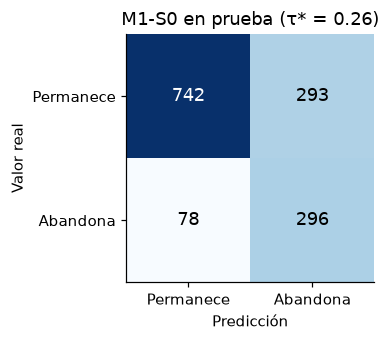

In [20]:
# Modelo seleccionado: la configuración con mayor ROC-AUC promedio en validación.
best_key = max(final, key=lambda k: final[k]["cv_auc_mean"])
info["best_by_cv_auc"] = best_key
B = final[best_key]
m = B["test_at_tau"]
print(f"Modelo seleccionado: {best_key} (AUC VC = {B['cv_auc_mean']:.3f}; τ* = {B['tau']:.2f})")
print(f"Matriz de confusión en prueba: VP = {m['tp']}, FN = {m['fn']}, FP = {m['fp']}, VN = {m['tn']}")
contactados = (m["tp"] + m["fp"]) / len(yte)
print(f"Contactando al {100 * contactados:.1f} % de la cartera se llega al {100 * m['recall']:.1f} % "
      f"de quienes abandonan; Precision {m['precision']:.3f} = {m['precision'] / yte.mean():.1f} veces la tasa base")
print(f"Recall en validación con τ*: {B['oof_at_tau']['recall']:.3f} | en prueba: {m['recall']:.3f}")
print(f"Con τ = 0,5 en prueba el Recall sería {B['test_at_05']['recall']:.3f}")

fig, ax = plt.subplots(figsize=(3.6, 3.2))
cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["Permanece", "Abandona"]); ax.set_yticks([0, 1], ["Permanece", "Abandona"])
ax.set_xlabel("Predicción"); ax.set_ylabel("Valor real")
ax.set_title(f"{best_key} en prueba (τ* = {B['tau']:.2f})")
plt.tight_layout()
plt.show()

In [21]:
# Hipótesis H1: Recall ≥ 0,80 y ROC-AUC ≥ 0,85 en prueba.
cumplen_recall = [k for k, v in final.items() if v["test_at_tau"]["recall"] >= 0.80]
auc_max = max(final.items(), key=lambda kv: kv[1]["test_at_tau"]["auc"])
print(f"Configuraciones con Recall ≥ 0,80 en prueba: {len(cumplen_recall)} de 9 -> {cumplen_recall}")
print(f"Configuraciones con ROC-AUC ≥ 0,85: {sum(v['test_at_tau']['auc'] >= 0.85 for v in final.values())}; "
      f"máximo {auc_max[1]['test_at_tau']['auc']:.3f} ({auc_max[0]})")
print("H1 se rechaza: se cumple la meta de detección, pero no la de separación.")

Configuraciones con Recall ≥ 0,80 en prueba: 7 de 9 -> ['M1-S2', 'M2-S0', 'M2-S1', 'M2-S2', 'M3-S0', 'M3-S1', 'M3-S2']
Configuraciones con ROC-AUC ≥ 0,85: 0; máximo 0.844 (M3-S0)
H1 se rechaza: se cumple la meta de detección, pero no la de separación.


## 11. Efecto del umbral y del balanceo (Fig. 2, Tabla 4, hipótesis H2)

τ* = 0,26: Recall 0.806 | Precision 0.516
τ = 0,50: Recall 0.548 | Precision 0.653


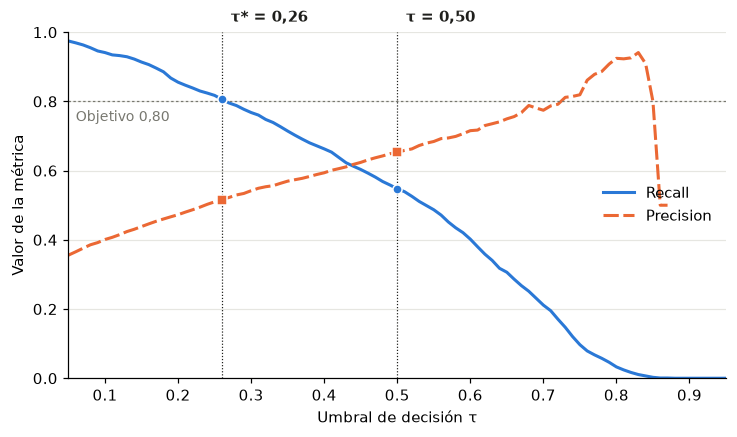

In [22]:
# Fig. 2: Recall y Precision del modelo seleccionado según el umbral (predicciones fuera de pliegue).
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#1f1f1c", "#77776f"
com = lambda v, d=2: f"{v:.{d}f}".replace(".", ",")
cur = B["threshold_curve"]
t = [r[0] for r in cur]; rec = [r[1] for r in cur]
prec = [r[2] if r[1] > 0 else float("nan") for r in cur]   # sin alertas no hay precisión
tau = B["tau"]

fig, ax = plt.subplots(figsize=(6.8, 4.3))
ax.plot(t, rec, color=BLUE, lw=2, label="Recall")
ax.plot(t, prec, color=ORANGE, lw=2, ls=(0, (5, 1.5)), label="Precision")
ax.axhline(0.80, color=MUTED, lw=0.8, ls=(0, (2, 2)))
ax.text(0.06, 0.775, "Objetivo 0,80", ha="left", va="top", color=MUTED, fontsize=9)
for x, lab in [(tau, f"τ* = {com(tau)}"), (0.5, "τ = 0,50")]:
    ax.axvline(x, color=INK, lw=0.8, ls=(0, (1, 1.5)))
    i = min(range(len(t)), key=lambda k: abs(t[k] - x))
    ax.plot([x], [rec[i]], "o", color=BLUE, mec="white", zorder=5)
    ax.plot([x], [prec[i]], "s", color=ORANGE, mec="white", zorder=5)
    ax.text(x + 0.012, 1.02, lab, ha="left", va="bottom", color=INK, fontweight="bold")
    print(f"{lab}: Recall {rec[i]:.3f} | Precision {prec[i]:.3f}")
ax.set_xlim(0.05, 0.95); ax.set_ylim(0, 1.0)
ax.set_xlabel("Umbral de decisión τ"); ax.set_ylabel("Valor de la métrica")
ax.legend(loc="center right", frameon=False)
ax.grid(axis="y", color="#e6e6e1"); ax.set_axisbelow(True)
plt.tight_layout(rect=(0, 0, 1, 0.95))
os.makedirs("resultados", exist_ok=True)
plt.savefig("resultados/fig2_umbral.png", dpi=300)
plt.show()

In [23]:
# Tabla 4: Recall en validación (promedio de los 5 pliegues y mínimo–máximo).
# La primera columna es la referencia sin adaptaciones (S0 con τ = 0,5); las demás usan τ* de cada configuración.
def celda(v):
    v = np.array(v)
    return f"{v.mean():.3f} ({v.min():.3f}–{v.max():.3f})"

tabla4 = pd.DataFrame({
    "S0, τ = 0,5": {m: celda(final[f"{m}-S0"]["fold_recall_05"]) for m in ["M1", "M2", "M3"]},
    **{f"{s}, τ*": {m: celda(final[f"{m}-{s}"]["fold_recall_tau"]) for m in ["M1", "M2", "M3"]}
       for s in ["S0", "S1", "S2"]},
})
tabla4

,"S0, τ = 0,5","S0, τ*","S1, τ*","S2, τ*"
M1,0.548 (0.505–0.629),0.806 (0.756–0.853),0.803 (0.753–0.856),0.805 (0.763–0.846)
M2,0.558 (0.525–0.572),0.801 (0.766–0.823),0.801 (0.783–0.829),0.815 (0.736–0.876)
M3,0.532 (0.508–0.582),0.806 (0.759–0.866),0.806 (0.756–0.856),0.800 (0.749–0.849)


In [24]:
# Hipótesis H2: ¿las adaptaciones mejoran el Recall en los cinco pliegues y con qué pérdida de precisión?
ganancias, perdidas = [], []
for mo in ["M1", "M2", "M3"]:
    ref = final[f"{mo}-S0"]
    r0 = np.array(ref["fold_recall_05"])
    for s in ["S0", "S1", "S2"]:
        v = final[f"{mo}-{s}"]
        ganancias += list(np.array(v["fold_recall_tau"]) - r0)
        perdidas.append(ref["oof_at_05"]["precision"] - v["oof_at_tau"]["precision"])
print(f"Mejora de Recall por pliegue: entre +{min(ganancias):.2f} y +{max(ganancias):.2f} "
      f"(todas positivas: {all(g > 0 for g in ganancias)})")
print(f"Pérdida de Precision: entre {min(perdidas):.2f} y {max(perdidas):.2f}")
print("τ* de S1:", {k: v["tau"] for k, v in final.items() if k.endswith("S1")},
      "-> los pesos por clase equivalen a desplazar el umbral")
for mo in ["M1", "M2", "M3"]:
    d = final[f"{mo}-S0"]["cv_auc_mean"] - final[f"{mo}-S2"]["cv_auc_mean"]
    r = final[f"{mo}-S2"]["seconds"] / final[f"{mo}-S0"]["seconds"]
    print(f"{mo}: SMOTE-NC reduce el AUC VC en {d:.3f} y tarda {r:.1f} veces más que S0")

Mejora de Recall por pliegue: entre +0.17 y +0.30 (todas positivas: True)
Pérdida de Precision: entre 0.12 y 0.18
τ* de S1: {'M1-S1': 0.5, 'M2-S1': 0.46, 'M3-S1': 0.48} -> los pesos por clase equivalen a desplazar el umbral
M1: SMOTE-NC reduce el AUC VC en 0.006 y tarda 8.2 veces más que S0
M2: SMOTE-NC reduce el AUC VC en 0.008 y tarda 5.4 veces más que S0
M3: SMOTE-NC reduce el AUC VC en 0.010 y tarda 10.9 veces más que S0


## 12. Influencia de los hiperparámetros

In [25]:
# ROC-AUC de validación según cada hiperparámetro (mejor valor de la rejilla, estrategia S0).
s0 = cv_grid[cv_grid.strategy == "S0"]
print("M1 – AUC VC por C y penalización:")
print(s0[s0.model == "M1"].pivot_table(index="C", columns="penalty", values="auc_mean").round(3))
m2 = s0[s0.model == "M2"]
print("\nM2 – mejor AUC VC por profundidad máxima:")
print(m2.groupby("max_depth").auc_mean.max().round(3).to_string())
print("\nM2 – mejor AUC VC por α de poda:")
print(m2.groupby("ccp_alpha").auc_mean.max().round(3).to_string())
print("\nM2 – mejor AUC VC por tamaño mínimo de hoja:")
print(m2.groupby("min_samples_leaf").auc_mean.max().round(3).to_string())
print("\nM3 – mejor AUC VC por profundidad del árbol que segmenta:")
print(s0[s0.model == "M3"].groupby("depth").auc_mean.max().round(3).to_string())

M1 – AUC VC por C y penalización:
penalty     l1     l2
C                    
0.01     0.823  0.840
0.10     0.845  0.845
1.00     0.845  0.845
10.00    0.846  0.846

M2 – mejor AUC VC por profundidad máxima:
max_depth
3.0     0.818
4.0     0.826
5.0     0.829
6.0     0.827
8.0     0.825
10.0    0.824

M2 – mejor AUC VC por α de poda:
ccp_alpha
0.000    0.829
0.001    0.824
0.005    0.802
0.010    0.798

M2 – mejor AUC VC por tamaño mínimo de hoja:
min_samples_leaf
5.0     0.827
10.0    0.826
20.0    0.826
50.0    0.829

M3 – mejor AUC VC por profundidad del árbol que segmenta:
depth
2.0    0.845
3.0    0.842


## 13. Curvas ROC en prueba (Fig. 3)

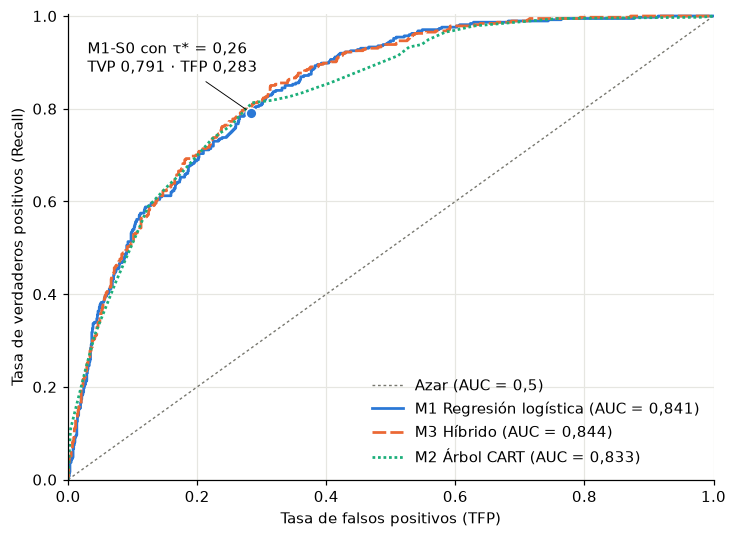

El árbol M2-S0 tiene 29 hojas, por lo que solo puede producir 29 probabilidades distintas (una por hoja): por eso su curva avanza por tramos rectos.


In [26]:
fig, ax = plt.subplots(figsize=(6.8, 5))
ax.plot([0, 1], [0, 1], color=MUTED, lw=0.9, ls=(0, (2, 2)), label="Azar (AUC = 0,5)")
for key, name, col, ls in [("M1-S0", "M1 Regresión logística", BLUE, "-"),
                           ("M3-S0", "M3 Híbrido", ORANGE, (0, (5, 1.5))),
                           ("M2-S0", "M2 Árbol CART", AQUA, (0, (1, 1)))]:
    fpr, tpr = final[key]["roc_test"]
    ax.plot(fpr, tpr, color=col, lw=1.8, ls=ls, label=f"{name} (AUC = {com(final[key]['test_at_tau']['auc'], 3)})")
x0, y0 = m["fp"] / (m["fp"] + m["tn"]), m["recall"]
ax.plot([x0], [y0], "o", ms=7, color=BLUE, mec="white", zorder=6)
ax.annotate(f"{best_key} con τ* = {com(tau)}\nTVP {com(y0, 3)} · TFP {com(x0, 3)}", xy=(x0, y0),
            xytext=(0.03, 0.88), arrowprops=dict(arrowstyle="-", lw=0.6))
ax.set_xlim(0, 1); ax.set_ylim(0, 1.005)
ax.set_xlabel("Tasa de falsos positivos (TFP)"); ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.legend(loc="lower right", frameon=False)
ax.grid(color="#e6e6e1"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("resultados/fig3_roc.png", dpi=300)
plt.show()
print(f"El árbol M2-S0 tiene {modelos['M2-S0'][1].get_n_leaves()} hojas, por lo que solo puede producir "
      f"{modelos['M2-S0'][1].get_n_leaves()} probabilidades distintas (una por hoja): por eso su curva "
      f"avanza por tramos rectos.")

## 14. Interpretabilidad (hipótesis H3)

In [27]:
# M2-S0: importancia de los atributos en el árbol (reducción de Gini).
pre2, tree2 = modelos["M2-S0"]
imp = pd.Series(tree2.feature_importances_, index=pre2.get_feature_names_out())
imp = imp[imp > 0].sort_values(ascending=False)
print(f"Hojas del árbol M2-S0: {tree2.get_n_leaves()}")
print((100 * imp).round(1).to_string())
cargos = imp[[c for c in imp.index if c in ("MonthlyCharges", "TotalCharges", "avg_charge", "charge_diff")]].sum()
print(f"\nImportancia conjunta de los atributos de cargos: {100 * cargos:.0f} %")

Hojas del árbol M2-S0: 29
Contract_Month-to-month           51.6
InternetService_Fiber optic       16.4
tenure                            16.2
TotalCharges                       3.8
PaymentMethod_Electronic check     3.0
avg_charge                         2.4
MonthlyCharges                     2.0
InternetService_No                 1.7
Contract_Two year                  0.8
PaperlessBilling                   0.5
Contract_One year                  0.4
StreamingMovies                    0.4
PhoneService                       0.3
gender                             0.2
Dependents                         0.2
SeniorCitizen                      0.0

Importancia conjunta de los atributos de cargos: 8 %


In [28]:
# Primeras reglas del árbol (hasta profundidad 3), legibles para el área comercial.
print(export_text(tree2, feature_names=list(pre2.get_feature_names_out()), max_depth=3))

|--- Contract_Month-to-month <= 0.50
|   |--- MonthlyCharges <= 0.95
|   |   |--- Contract_One year <= 0.50
|   |   |   |--- PaymentMethod_Electronic check <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- PaymentMethod_Electronic check >  0.50
|   |   |   |   |--- class: 0
|   |   |--- Contract_One year >  0.50
|   |   |   |--- StreamingMovies <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- StreamingMovies >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- MonthlyCharges >  0.95
|   |   |--- Contract_Two year <= 0.50
|   |   |   |--- Dependents <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Dependents >  0.50
|   |   |   |   |--- class: 0
|   |   |--- Contract_Two year >  0.50
|   |   |   |--- TotalCharges <= 2.39
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- TotalCharges >  2.39
|   |   |   |   |--- class: 0
|--- Contract_Month-to-month >  0.50
|   |--- InternetService_Fibe

In [29]:
# M1-S0: coeficientes y razones de momios e^w (las numéricas están estandarizadas: efecto por cada
# desviación estándar adicional; las categorías se comparan con la de referencia).
pre1, lr1 = modelos["M1-S0"]
coef = pd.DataFrame({"w": lr1.coef_[0], "odds": np.exp(lr1.coef_[0])}, index=pre1.get_feature_names_out())
coef.reindex(coef.w.abs().sort_values(ascending=False).index).round(3)

,w,odds
InternetService_No,-2.193,0.112
InternetService_Fiber optic,2.177,8.818
Contract_Two year,-1.363,0.256
tenure,-1.291,0.275
n_services,1.173,3.231
MonthlyCharges,-0.844,0.430
avg_charge,-0.828,0.437
OnlineSecurity,-0.784,0.456
TechSupport,-0.731,0.482
Contract_One year,-0.698,0.498


In [30]:
# M3-S0: segmentos del árbol que alimenta a las regresiones logísticas por hoja.
pre3, llm = modelos["M3-S0"]
nombres3 = list(pre3.get_feature_names_out())
print(export_text(llm.tree, feature_names=nombres3))

# El corte de tenure está en unidades estandarizadas: lo convertimos a meses.
d = Xtr.copy(); d["y"] = ytr; d["fiber"] = (d.InternetService == "Fiber optic").astype(int)
z = llm.tree.tree_.threshold[0]
assert nombres3[llm.tree.tree_.feature[0]] == "tenure"
tenure_sd = d.tenure.std(ddof=0)
cut = int(np.floor(d.tenure.mean() + z * tenure_sd))
nuevo = d.tenure <= cut
print(f"Corte de antigüedad: hasta {cut} meses (1 desviación estándar de tenure = {tenure_sd:.1f} meses)")
print(f"Abandono de clientes nuevos con fibra:     {100 * d[nuevo & (d.fiber == 1)].y.mean():.1f} % "
      f"(n = {(nuevo & (d.fiber == 1)).sum()})")
print(f"Abandono de clientes antiguos sin fibra:   {100 * d[~nuevo & (d.fiber == 0)].y.mean():.1f} % "
      f"(n = {(~nuevo & (d.fiber == 0)).sum()})")
print("Abandono por tipo de contrato (entrenamiento):", (100 * d.groupby("Contract").y.mean()).round(1).to_dict())

|--- tenure <= -0.65
|   |--- InternetService_Fiber optic <= 0.50
|   |   |--- class: 0
|   |--- InternetService_Fiber optic >  0.50
|   |   |--- class: 1
|--- tenure >  -0.65
|   |--- InternetService_Fiber optic <= 0.50
|   |   |--- class: 0
|   |--- InternetService_Fiber optic >  0.50
|   |   |--- class: 0

Corte de antigüedad: hasta 16 meses (1 desviación estándar de tenure = 24.6 meses)
Abandono de clientes nuevos con fibra:     68.3 % (n = 868)
Abandono de clientes antiguos sin fibra:   6.1 % (n = 1977)
Abandono por tipo de contrato (entrenamiento): {'Month-to-month': 42.7, 'One year': 11.1, 'Two year': 2.9}


In [31]:
# Colinealidad: el efecto del cargo mensual no puede aislarse.
print(f"Correlación MonthlyCharges – fibra óptica: r = {np.corrcoef(d.MonthlyCharges, d.fiber)[0, 1]:.2f}")
print(f"Correlación MonthlyCharges – avg_charge:  r = {np.corrcoef(d.MonthlyCharges, d.avg_charge)[0, 1]:.2f}")

# Variante parsimoniosa de M1 con L1 (C = 0,1): selecciona atributos.
pre, A, b_ = prepare(Xtr, ytr, "S0", True, SEED)
l1 = build("M1", dict(C=0.1, penalty="l1"), None).fit(A, b_)
nombres = pre.get_feature_names_out()
info["m1_l1"] = dict(n_features=int(len(l1.coef_[0])), n_zero=int((l1.coef_[0] == 0).sum()),
                     test_auc=float(roc_auc_score(yte, l1.predict_proba(pre.transform(Xte))[:, 1])))
print(f"\nVariante L1: elimina {info['m1_l1']['n_zero']} de {info['m1_l1']['n_features']} atributos "
      f"y obtiene ROC-AUC {info['m1_l1']['test_auc']:.3f} en prueba")
print("Atributos eliminados:", [n for n, w in zip(nombres, l1.coef_[0]) if w == 0])
print("Razón de momios de MonthlyCharges: L2 =", round(float(coef.loc["MonthlyCharges", "odds"]), 2),
      "| L1 =", round(float(np.exp(l1.coef_[0][list(nombres).index("MonthlyCharges")])), 2))

Correlación MonthlyCharges – fibra óptica: r = 0.79
Correlación MonthlyCharges – avg_charge:  r = 0.99



Variante L1: elimina 8 de 26 atributos y obtiene ROC-AUC 0.841 en prueba
Atributos eliminados: ['charge_diff', 'InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Mailed check', 'gender', 'Partner', 'StreamingTV', 'StreamingMovies']
Razón de momios de MonthlyCharges: L2 = 0.43 | L1 = 2.04


## 15. Implicancias éticas: auditoría de sesgos del modelo seleccionado

In [32]:
# Desempeño del modelo seleccionado por grupo (género y adulto mayor) en el conjunto de prueba.
pb = np.array(B["p_test"])
fair = {}
for col, labels in [("gender", {0: "Mujer", 1: "Hombre"}),
                    ("SeniorCitizen", {0: "No adulto mayor", 1: "Adulto mayor"})]:
    for v, lab in labels.items():
        msk = (Xte[col] == v).to_numpy()
        pred = (pb[msk] >= B["tau"]).astype(int)
        fair[lab] = dict(n=int(msk.sum()), churn_rate=float(yte[msk].mean()),
                         recall=float(recall_score(yte[msk], pred)),
                         precision=float(precision_score(yte[msk], pred, zero_division=0)),
                         flagged=float(pred.mean()))
info["fairness"] = fair
pd.DataFrame(fair).T.rename(columns={"churn_rate": "tasa de abandono", "flagged": "alertados"}).round(3)

,n,tasa de abandono,recall,precision,alertados
Mujer,687.0,0.281,0.782,0.526,0.418
Hombre,722.0,0.251,0.801,0.480,0.418
No adulto mayor,1187.0,0.233,0.743,0.468,0.369
Adulto mayor,222.0,0.441,0.929,0.603,0.680


## 16. Guardado de resultados

In [33]:
# Guardamos las métricas de las 9 configuraciones y la rejilla completa de validación cruzada.
cv_grid.to_csv("resultados/cv_grid.csv", index=False)
with open("resultados/results.json", "w", encoding="utf-8") as fh:
    json.dump(dict(info=info, final=final), fh, indent=1)
print("Archivos guardados en resultados/:", sorted(os.listdir("resultados")))

Archivos guardados en resultados/: ['cv_grid.csv', 'fig2_umbral.png', 'fig3_roc.png', 'results.json']
